# Control adaptativo con EKF: de la asignación de polos a un lazo certificado
### Un seguidor móvil que mide únicamente posición

**El Inge de Control · Tutorial en Python · Octubre de 2026**

Estudiaremos un movimiento de traslación descrito por
$$
m\ddot p+b\dot p=u,\qquad y_k=p_k+\nu_k.
$$
El EKF estimará simultáneamente posición, velocidad y fricción. Después compararemos:

1. Una posible regla adaptativa.
2. El EKF combinado con LQR.

**Alcance físico.** Es un modelo longitudinal 1D, con masa conocida y fricción viscosa. No modela orientación, ruedas, deslizamiento, fricción seca, saturación ni evitación de colisiones. “Seguidor” significa seguir una posición de referencia; para seguir un líder a distancia $d$, define $r=p_{\mathrm{líder}}-d$.

## Preparación y convenciones

Requisitos: Python 3.10 o posterior, NumPy, SciPy, Matplotlib, pandas y CVXPY con CLARABEL. CVXPY sólo se utiliza en el diseño fuera de línea del certificado; el filtro en línea usa NumPy. Si faltan paquetes, descomenta la siguiente celda. No se necesita `python-control` ni Plotly.

In [1]:
# %pip install numpy scipy matplotlib pandas cvxpy clarabel

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import cvxpy as cp
from itertools import product
from scipy.linalg import (expm, solve_discrete_are, solve_continuous_lyapunov,
                          eigvalsh)
from scipy.signal import place_poles
from IPython.display import display

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({
    'figure.figsize': (10.5, 4.0), 'figure.dpi': 120,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .22, 'font.size': 10,
    'axes.prop_cycle': plt.cycler(color=['#087e8b', '#e06c35', '#6157a5', '#343f56'])
})
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | '
      f'SciPy {scipy.__version__} | CVXPY {cp.__version__}')

Python 3.13.15 | NumPy 2.1.3 | SciPy 1.16.3 | CVXPY 1.6.7


Usaremos $s=[p,v]^T$ para el estado físico y $z=[p,v,b]^T$ para el estado aumentado. Así evitamos usar $x$ simultáneamente como posición y vector.

| Símbolo | Significado |
|---|---|
| $m$, $b$, $u$ | Masa [kg], fricción viscosa [N·s/m], fuerza [N] |
| $P_k$ | Covarianza aproximada del EKF |
| $Q_{\rm EKF},R_y$ | Covarianzas de proceso y medición por muestra |
| $Q_c,R_u$ | Pesos del costo de control; **no** son covarianzas |
| $S$ | Solución de Riccati del LQR |
| $P_c$ | Matriz de Lyapunov común del lazo certificado |

Los parámetros de abajo son elecciones didácticas, no datos identificados de un vehículo real. El intervalo físico $[b_{\min},b_{\max}]$ se debe justificar experimentalmente antes de usar el certificado en una aplicación.

In [3]:
MASS = 1.0
DT = 0.02                         # 50 Hz
B_PHYS = (0.5, 5.0)               # hipótesis física del certificado
B_EST = (0.05, 20.0)              # protección numérica amplia del EKF
SIGMA_Y = 0.03                    # metros; única medición
R_Y = SIGMA_Y**2
Q_EKF = np.diag([1e-7, 2e-5, 2e-4])
Q_TRUE = np.diag([1e-7, 2e-5])
Q_COST = np.diag([10.0, 1.0])
R_COST = 0.1
H = np.array([[1.0, 0.0, 0.0]])
C = np.array([[1.0, 0.0]])
P_INITIAL = np.diag([0.05**2, 0.5**2, 2.0**2])

## Modelo aumentado y discretización

Para $b$ constante, o aproximadamente constante durante una muestra,
$$
\dot z=\begin{bmatrix}v\\ (u-bv)/m\\0\end{bmatrix},\qquad y=[1\;0\;0]z+\nu.
$$
Aunque la planta es lineal si $b$ se conoce, el modelo aumentado es **no lineal** por el producto $bv$.

El Euler de los adjuntos es
$$
f_E(z,u)=\begin{bmatrix}p+T_sv\\v+T_s(u-bv)/m\\b\end{bmatrix},\quad
F_E=\begin{bmatrix}1&T_s&0\\0&1-T_sb/m&-T_sv/m\\0&0&1\end{bmatrix}.
$$
Esto sirve para entender el EKF, pero un certificado de Euler no es automáticamente un certificado de la planta física muestreada.

Aquí mantendremos $u_k$ y $b_k$ constantes en cada intervalo. Definiendo
$$
a=e^{-bT_s/m},\qquad g=\frac{m(1-a)}b,\qquad h=\frac{T_s-g}b,
$$
obtenemos la discretización ZOH exacta:
$$
s_{k+1}=A_d(b_k)s_k+B_d(b_k)u_k+w_k,\quad
A_d=\begin{bmatrix}1&g\\0&a\end{bmatrix},\quad B_d=\begin{bmatrix}h\\g/m\end{bmatrix}.
$$
La fricción sigue un paseo aleatorio **en el filtro**, $b_{k+1}=b_k+w_{b,k}$. Es una forma de permitir adaptación, no una afirmación de que la fricción real sea gaussiana. Las covarianzas elegidas son discretas; al modificar $T_s$ no deben reutilizarse sin revisar su escala.

In [4]:
def zoh_coeff(b, dt=DT, mass=MASS):
    # El EKF se mantiene alejado de b=0; expm1 evita cancelación en 1-exp(-x).
    a = np.exp(-b*dt/mass)
    g = -mass*np.expm1(-b*dt/mass)/b
    h = (dt-g)/b
    return a, g, h

def model(b, dt=DT, mass=MASS):
    a, g, h = zoh_coeff(b, dt, mass)
    return np.array([[1.0, g], [0.0, a]]), np.array([[h], [g/mass]])

def f_aug(z, u):
    A, B = model(z[2])
    return np.r_[A @ z[:2] + B[:, 0]*u, z[2]]

def jac_aug(z, u):
    _, vel, b = z
    a, g, h = zoh_coeff(b)
    da = -DT*a/MASS
    dg = DT*a/b - MASS*(1.0-a)/b**2
    dh = -dg/b - (DT-g)/b**2
    return np.array([[1.0, g, dg*vel + dh*u],
                     [0.0, a, da*vel + dg*u/MASS],
                     [0.0, 0.0, 1.0]])

# Dos comprobaciones que sí detectan errores de modelado.
for b_test in [0.05, 0.5, 2.0, 5.0, 20.0]:
    Ac = np.array([[0., 1.], [0., -b_test/MASS]])
    Bc = np.array([[0.], [1./MASS]])
    exact = expm(np.block([[Ac, Bc], [np.zeros((1, 3))]])*DT)
    A, B = model(b_test)
    assert np.allclose(np.c_[A, B], exact[:2], atol=1e-11)
    z_test, u_test, eps = np.array([1., 0.7, b_test]), 2.3, 1e-6
    J_fd = np.column_stack([(f_aug(z_test+eps*np.eye(3)[i], u_test)
                            -f_aug(z_test-eps*np.eye(3)[i], u_test))/(2*eps)
                           for i in range(3)])
    assert np.allclose(jac_aug(z_test, u_test), J_fd, atol=2e-7)
print('ZOH y Jacobiano comprobados contra exponencial matricial y diferencias finitas.')

ZOH y Jacobiano comprobados contra exponencial matricial y diferencias finitas.


## ¿Se puede estimar la fricción midiendo sólo posición?

Con una entrada conocida, las primeras derivadas de la salida son
$$
y=p,\quad\dot y=v,\quad\ddot y=(u-bv)/m.
$$
La matriz de sensibilidades respecto a $[p,v,b]$ es
$$
\mathcal O_{\rm local}=
\begin{bmatrix}1&0&0\\0&1&0\\0&-b/m&-v/m\end{bmatrix},\qquad
\det\mathcal O_{\rm local}=-v/m.
$$
Si $v\ne0$, este test da rango completo. Si el vehículo permanece en reposo con $u=0$, cualquier $b$ produce la misma salida: no hay información para identificarlo. Que el determinante sea cero en **un instante** no implica imposibilidad permanente; una aceleración posterior puede aportar información.

Para estimación mantenida interesa la excitación a lo largo del tiempo; en este modelo, $\int_t^{t+T}v^2(\tau)\,d\tau$ es un indicador útil. No equivale por sí solo a un teorema completo de convergencia del EKF con posición ruidosa. Tampoco se deben calcular dos derivadas de la medición como sustituto del filtro: amplificarían mucho el ruido.

**Conflicto didáctico:** un regulador que llega rápido y se queda quieto puede controlar bien y dejar de aprender $b$. Un cambio de fricción cuando $v\approx0$ puede pasar inadvertido hasta el siguiente movimiento. Identificación y regulación son objetivos diferentes [1, 2].

## 5. EKF conjunto: predicción, corrección y diagnóstico

Desde el posterior $(\hat z_{k|k},P_{k|k})$, después de aplicar $u_k$:
$$
\hat z^-_{k+1}=f(\hat z_{k|k},u_k),\quad
P^-_{k+1}=F_kP_{k|k}F_k^T+Q_{\rm EKF},
$$
$$
\epsilon_{k+1}=y_{k+1}-H\hat z^-_{k+1},\quad
\Omega_{k+1}=HP^-_{k+1}H^T+R_y,\quad
L_{k+1}=P^-_{k+1}H^T\Omega_{k+1}^{-1},
$$
$$
\hat z_{k+1|k+1}=\hat z^-_{k+1}+L_{k+1}\epsilon_{k+1}.
$$
Usaremos la actualización de Joseph:
$$
P^+=(I-LH)P^-(I-LH)^T+LR_yL^T.
$$
Reduce problemas numéricos de simetría/positividad; no arregla una mala linealización o falta de observabilidad.

Recortamos únicamente $\hat b$ al intervalo amplio `B_EST`. Esto evita valores físicos absurdos y singularidades numéricas, pero no convierte al EKF en un filtro gaussiano exacto condicionado a restricciones. Las bandas $\hat b\pm2\sqrt{P_{bb}}$ serán **diagnósticas aproximadas**, no cotas duras para la estabilidad. El NIS es $\epsilon^2/\Omega$; esperar media cercana a 1 sólo tiene sentido si las hipótesis y la sintonización son razonables.

In [5]:
def ekf_step(zhat, P, u, y_next):
    F = jac_aug(zhat, u)                  # posterior anterior, no estado predicho
    zminus = f_aug(zhat, u)
    Pminus = F @ P @ F.T + Q_EKF
    innovation = float(y_next-zminus[0])
    omega = float(Pminus[0, 0]+R_Y)
    gain = Pminus[:, 0]/omega
    znew = zminus + gain*innovation
    raw_b = znew[2]
    znew[2] = np.clip(raw_b, *B_EST)
    J = np.eye(3)-np.outer(gain, H[0])
    Pnew = J @ Pminus @ J.T + R_Y*np.outer(gain, gain)
    Pnew = (Pnew+Pnew.T)/2
    return znew, Pnew, innovation**2/omega, raw_b != znew[2]

## Propuesta 1: asignación de polos adaptativa (“naive”)

Para una referencia constante $r$, define $e=p-r$, y aplica
$$
u=-k_p(\hat p-r)-k_v\hat v.
$$
Si los estados y la fricción se conocieran exactamente, el polinomio continuo sería
$$
s^2+\frac{b+k_v}{m}s+\frac{k_p}{m}.
$$
Igualándolo a $(s+p_1)(s+p_2)$, con $p_1,p_2>0$, se obtiene la regla correcta del PDF:
$$
\boxed{k_p=mp_1p_2,\qquad k_v=m(p_1+p_2)-\hat b.}
$$
La fricción real aparece en el amortiguamiento efectivo como
$$
b+k_v=m(p_1+p_2)+(b-\hat b).
$$
Una sobreestimación suficientemente grande puede hacerlo negativo. Para $m=1,p_1=2,p_2=3,b=2$, basta $\hat b>7$. No hace falta una conmutación complicada para perder estabilidad en ese caso.

Usamos esta ley continua con retención digital para conservar la idea. Sus polos digitales **no son exactamente** $e^{-p_iT_s}$. Si ese objetivo digital es imprescindible, hay que asignar polos de $A_d(\hat b)-B_d(\hat b)K$ directamente. Esa corrección tampoco resuelve por sí sola el problema de adaptación.

In [6]:
def gain_naive(bhat, poles=(2.0, 3.0)):
    p1, p2 = poles
    return np.array([MASS*p1*p2, MASS*(p1+p2)-bhat], dtype=float)

for bhat in [2.0, 9.0]:
    K = gain_naive(bhat)
    F_cont = np.array([[0., 1.], [-K[0]/MASS, -(2.0+K[1])/MASS]])
    print(f'b real=2, b estimada={bhat:g}: K={K}, polos reales={np.linalg.eigvals(F_cont)}')

b real=2, b estimada=2: K=[6. 3.], polos reales=[-2. -3.]
b real=2, b estimada=9: K=[ 6. -4.], polos reales=[1.+2.23607j 1.-2.23607j]


## Propuesta 2: EKF + LQR adaptativo

El LQR discreto usa $e_k=s_k-[r,0]^T$ y el costo determinista
$$
J=\sum_{k=0}^{\infty}(e_k^TQ_ce_k+u_k^TR_uu_k).
$$
Para un modelo fijo, se resuelve
$$
S=A_d^TSA_d-A_d^TSB_d(R_u+B_d^TSB_d)^{-1}B_d^TSA_d+Q_c,
$$
$$
K=(R_u+B_d^TSB_d)^{-1}B_d^TSA_d,\qquad u_k=-K\hat e_k.
$$
Se sustituye $b$ por $\hat b_k$ y se resuelve Riccati en cada muestra, midiendo sólo posición. El optimizador elige un compromiso entre seguimiento y esfuerzo para el **modelo congelado**, no el controlador adaptativo globalmente óptimo.

El LQG clásico combina LQR y KF para un modelo lineal conocido, con hipótesis adecuadas de ruido, costo y estabilizabilidad/detectabilidad. La separación explica cómo diseñar estimación y control. Hay también formulaciones LQG de tiempo variable conocido; recalcular una DARE de horizonte infinito usando un parámetro desconocido estimado en lazo cerrado no es esa formulación. En nuestro caso, el estado aumentado es no lineal, el EKF es aproximado y la entrada afecta la información disponible sobre $b$. No se heredan automáticamente optimalidad ni estabilidad [1].

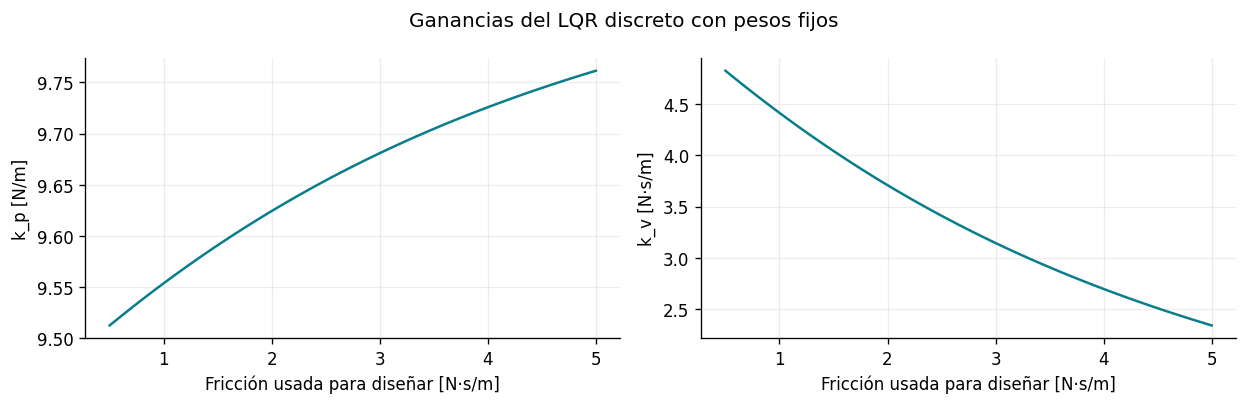

In [7]:
def gain_lqr(bhat, q=Q_COST, ru=R_COST):
    A, B = model(float(bhat))
    S = solve_discrete_are(A, B, q, np.array([[ru]]))
    return np.linalg.solve(np.array([[ru]])+B.T @ S @ B,
                           B.T @ S @ A).ravel()

b_grid = np.linspace(*B_PHYS, 100)
gains = np.array([gain_lqr(b) for b in b_grid])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
ax[0].plot(b_grid, gains[:, 0]); ax[0].set_ylabel('k_p [N/m]')
ax[1].plot(b_grid, gains[:, 1]); ax[1].set_ylabel('k_v [N·s/m]')
for a in ax: a.set_xlabel('Fricción usada para diseñar [N·s/m]')
fig.suptitle('Ganancias del LQR discreto con pesos fijos'); fig.tight_layout(); plt.show()

## Banco de simulación común

En cada muestra, las propuestas 1–2 usan el posterior disponible del EKF para decidir $u_k$. La planta avanza con ZOH, se mide **sólo posición**, y se hace la nueva predicción/corrección. El estado verdadero aparece únicamente en la simulación y en las métricas; jamás entra al controlador ni al filtro.

Comparamos con la misma semilla, condiciones iniciales, ruido y covarianzas. El EKF comienza con $\hat b_0=1$, mientras que $b=2$. Para referencias móviles añadimos
$$
u_{\rm ff}=m\ddot r+\hat b\dot r,\quad
u=u_{\rm ff}-K([\hat p,\hat v]^T-[r,\dot r]^T).
$$
Esta compensación es aproximada con $\hat b\ne b$ y muestreo. Una referencia móvil no es un equilibrio: la garantía rigurosa se formulará como seguimiento con perturbaciones, no como convergencia exacta prometida para toda trayectoria.

In [8]:
def reference(t, mode):
    if mode == 'setpoint':
        return 5.0, 0.0, 0.0
    if mode == 'moving':
        return 2.0+1.2*np.sin(0.7*t), 0.84*np.cos(0.7*t), -0.588*np.sin(0.7*t)
    raise ValueError(mode)

def friction(t, mode):
    if mode == 'constant':
        return 2.0
    return 2.0 if t < 8.0 else (4.2 if t < 18.0 else 1.0)

def simulate(method, duration=24., ref_mode='setpoint', b_mode='constant',
             seed=7, noisy=True, bhat0=1.0):
    rng = np.random.default_rng(seed)
    n = int(round(duration/DT))
    t = DT*np.arange(n+1)
    x = np.zeros((n+1, 2))
    z = np.zeros((n+1, 3)); z[0] = [0.15, 0.0, bhat0]
    obs = np.zeros((n+1, 2)); obs[0] = z[0, :2]
    cov = np.zeros((n+1, 3, 3)); cov[0] = P_INITIAL.copy()
    y = np.empty(n+1); y[0] = x[0, 0] + noisy*SIGMA_Y*rng.normal()
    u = np.empty(n); Khist = np.empty((n, 2)); nis = np.empty(n)
    theta = np.ones(n); margins = np.full(n, np.nan); clips = np.zeros(n, bool)
    refs = np.array([reference(ti, ref_mode) for ti in t])
    bs = np.array([friction(ti, b_mode) for ti in t])
    for k in range(n):
        if method == 'naive':
            K = gain_naive(z[k, 2]); feedback = z[k, :2]
        elif method == 'lqr':
            K = gain_lqr(z[k, 2]); feedback = z[k, :2]
        elif method == 'safe':
            K, theta[k], margins[k] = filter_gain(gain_lqr(z[k, 2]))
            feedback = obs[k]      # observador certificado, separado del EKF
        else:
            raise ValueError(method)
        rr, vr, ar = refs[k]
        bff = np.clip(z[k, 2], *B_PHYS)
        u[k] = MASS*ar + bff*vr - K @ (feedback-refs[k, :2])
        Khist[k] = K
        if method == 'safe':
            obs[k+1] = A0@obs[k] + B0[:, 0]*u[k] + L_OBS[:, 0]*(y[k]-obs[k, 0])
        A, B = model(bs[k])
        x[k+1] = A@x[k] + B[:, 0]*u[k] + noisy*np.sqrt(np.diag(Q_TRUE))*rng.normal(size=2)
        y[k+1] = x[k+1, 0]+noisy*SIGMA_Y*rng.normal()
        z[k+1], cov[k+1], nis[k], clips[k] = ekf_step(z[k], cov[k], u[k], y[k+1])
    return dict(t=t, x=x, z=z, obs=obs, P=cov, y=y, u=u, K=Khist,
                nis=nis, b=bs, ref=refs, theta=theta, margin=margins,
                clipped=clips, method=method)

NAMES = {'naive': 'Polos + EKF', 'lqr': 'LQR + EKF', 'safe': 'LQR filtrado + observador'}

def metrics(r):
    e = r['x'][:, 0]-r['ref'][:, 0]
    mask = r['t'] >= 4.0
    stage = np.einsum('ni,ij,nj->n', r['x'][:-1]-r['ref'][:-1, :2], Q_COST,
                      r['x'][:-1]-r['ref'][:-1, :2])+R_COST*r['u']**2
    return {'Método': NAMES[r['method']], 'RMSE p [m]': np.sqrt(np.mean(e**2)),
            'RMSE p desde 4 s [m]': np.sqrt(np.mean(e[mask]**2)),
            'RMSE b': np.sqrt(np.mean((r['z'][mask, 2]-r['b'][mask])**2)),
            'Esfuerzo ∫u²dt': DT*np.sum(r['u']**2), 'Pico |u| [N]': np.max(abs(r['u'])),
            'Costo finito ×dt': DT*np.sum(stage), 'Recortes b': int(r['clipped'].sum())}

def plot_comparison(results, title):
    fig, ax = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
    first = results[0]
    ax[0, 0].plot(first['t'], first['ref'][:, 0], 'k--', label='Referencia')
    ax[1, 0].plot(first['t'], first['b'], 'k--', label='Fricción real')
    for rr in results:
        t, label = rr['t'], NAMES[rr['method']]
        ax[0, 0].plot(t, rr['x'][:, 0], label=label)
        ax[0, 1].plot(t, rr['x'][:, 0]-rr['ref'][:, 0], label=label)
        ax[1, 0].plot(t, rr['z'][:, 2], label=label)
        ax[1, 1].plot(t[:-1], rr['u'], label=label)
        ax[2, 0].plot(t[:-1], rr['K'][:, 0], label=label)
        ax[2, 1].plot(t[:-1], rr['K'][:, 1], label=label)
    for a, lab in zip(ax.ravel(), ['Posición [m]', 'Error p-r [m]', 'Fricción [N·s/m]',
                                  'Fuerza [N]', 'k_p [N/m]', 'k_v [N·s/m]']):
        a.set_ylabel(lab)
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    for a in ax[-1]: a.set_xlabel('Tiempo [s]')
    fig.suptitle(title); fig.tight_layout(); plt.show()

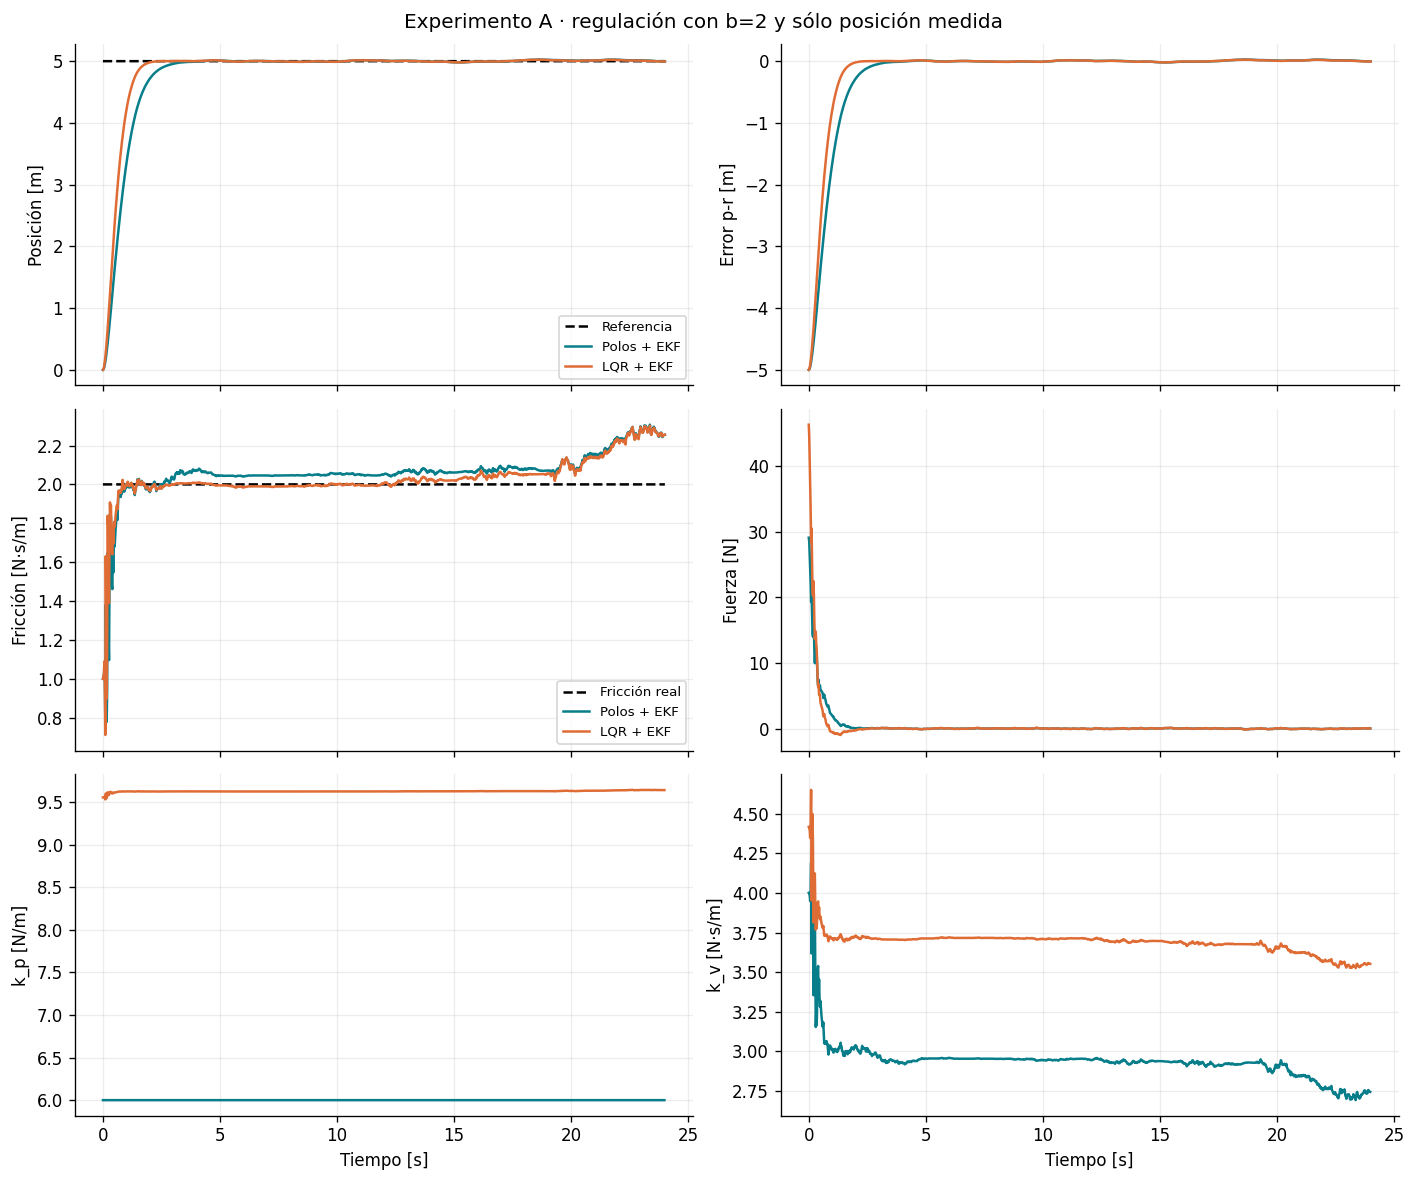

,RMSE p [m],RMSE p desde 4 s [m],RMSE b,Esfuerzo ∫u²dt,Pico |u| [N],Costo finito ×dt,Recortes b
Método,,,,,,,
Polos + EKF,0.7546,0.0117,0.1124,142.4493,29.1000,165.2593,0
LQR + EKF,0.6453,0.0105,0.0989,282.6321,46.3349,148.7996,0


In [9]:
reg_naive = simulate('naive')
reg_lqr = simulate('lqr')
plot_comparison([reg_naive, reg_lqr], 'Experimento A · regulación con b=2 y sólo posición medida')
display(pd.DataFrame([metrics(reg_naive), metrics(reg_lqr)]).set_index('Método').round(4))

### Cómo leer el experimento A

Primero observa el transitorio, el esfuerzo inicial y la estimación de $b$. Después observa qué ocurre cuando la velocidad tiende a cero. Un error pequeño de posición no demuestra que $\hat b$ sea correcto. Los pesos LQR y los polos elegidos representan compromisos diferentes; no hay razón para que una propuesta gane en **todas** las métricas.

El costo de la tabla se evalúa con estados verdaderos sólo para comparar simulaciones. Es un costo finito multiplicado por $T_s$; con ruido persistente no corresponde al valor determinista infinito $e_0^TSe_0$. El esfuerzo $\int u^2dt$ no es energía mecánica: esta última depende del trabajo $\int uv\,dt$. Una realización favorable tampoco es evidencia universal de optimalidad o estabilidad adaptativa.

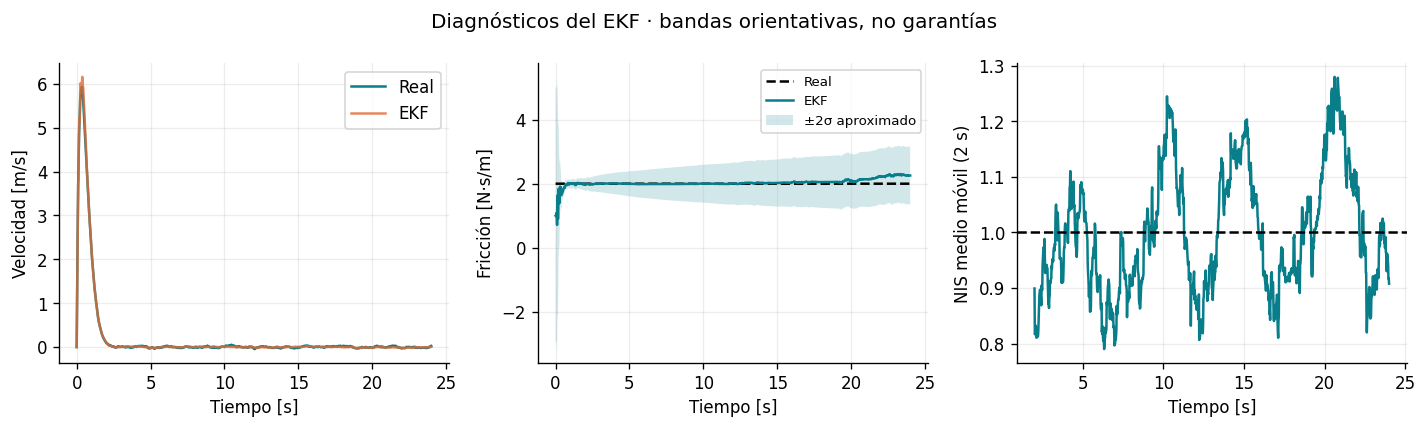

In [10]:
rr = reg_lqr
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].plot(rr['t'], rr['x'][:, 1], label='Real')
ax[0].plot(rr['t'], rr['z'][:, 1], label='EKF', alpha=.8)
ax[0].set_ylabel('Velocidad [m/s]'); ax[0].legend()
sd = np.sqrt(rr['P'][:, 2, 2])
ax[1].plot(rr['t'], rr['b'], 'k--', label='Real')
ax[1].plot(rr['t'], rr['z'][:, 2], label='EKF')
ax[1].fill_between(rr['t'], rr['z'][:, 2]-2*sd, rr['z'][:, 2]+2*sd,
                   alpha=.18, label='±2σ aproximado')
ax[1].set_ylabel('Fricción [N·s/m]'); ax[1].legend(fontsize=8)
rolling_nis = pd.Series(rr['nis']).rolling(100, min_periods=100).mean()
ax[2].plot(rr['t'][1:], rolling_nis); ax[2].axhline(1, ls='--', color='k')
ax[2].set_ylabel('NIS medio móvil (2 s)')
for a in ax: a.set_xlabel('Tiempo [s]')
fig.suptitle('Diagnósticos del EKF · bandas orientativas, no garantías'); fig.tight_layout(); plt.show()

## Por qué recalcular ganancias no basta

### Tres problemas diferentes

1. **Modelo equivocado.** $A_d(\hat b)-B_d(\hat b)K$ puede ser estable y el lazo con $b$ real no serlo. El ejemplo $\hat b=9,b=2$ de la propuesta 1 ya lo muestra.
2. **Cambio de dinámica.** Para $e_{k+1}=F_ke_k$, la solución depende del producto $F_{k-1}\cdots F_1F_0$. Tener $\rho(F_k)<1$ en cada muestra no basta para que ese producto decaiga.
3. **Estimación y control acoplados.** Con $\tilde s=s-\hat s$, el error de estimación entra como una perturbación $B_dK\tilde s$. El EKF aumentado no tiene, en general, una garantía global de convergencia; además, controlar modifica la excitación que permite estimar $b$.

Para ver el punto 2 mediante Riccati, si cada $S_k$ es una matriz de Lyapunov del modelo congelado, sólo sabes algo sobre
$F_k^TS_kF_k-S_k$. Pero para $V_k=e_k^TS_ke_k$, el cambio real es
$$
V_{k+1}-V_k=e_k^T\big(F_k^TS_{k+1}F_k-S_k\big)e_k.
$$
Falta controlar el término $F_k^T(S_{k+1}-S_k)F_k$. En continuo aparece el análogo $\dot S$. Una gráfica de polos instantáneos no contiene esa información [3, 4].

### Contraejemplo dentro de la forma mecánica de segundo orden

Considera $m=1,b=0.1,k_v=0.1$ y alterna $k_p=1$ con $k_p=100$. Los dos sistemas
$$
F_1=\begin{bmatrix}0&1\\-1&-0.2\end{bmatrix},\qquad
F_2=\begin{bmatrix}0&1\\-100&-0.2\end{bmatrix}
$$
tienen polos con parte real $-0.1$. Sin embargo, la conmutación siguiente produce crecimiento. Es un ejemplo construido para refutar la regla general de los polos congelados; **no afirma que el LQR con los pesos anteriores genere esta secuencia**.

Polos F1: [-0.1+0.99499j -0.1-0.99499j]
Polos F2: [-0.1+9.9995j -0.1-9.9995j]
T1=1.5787 s, T2=0.1571 s; radio espectral del ciclo=8.4484


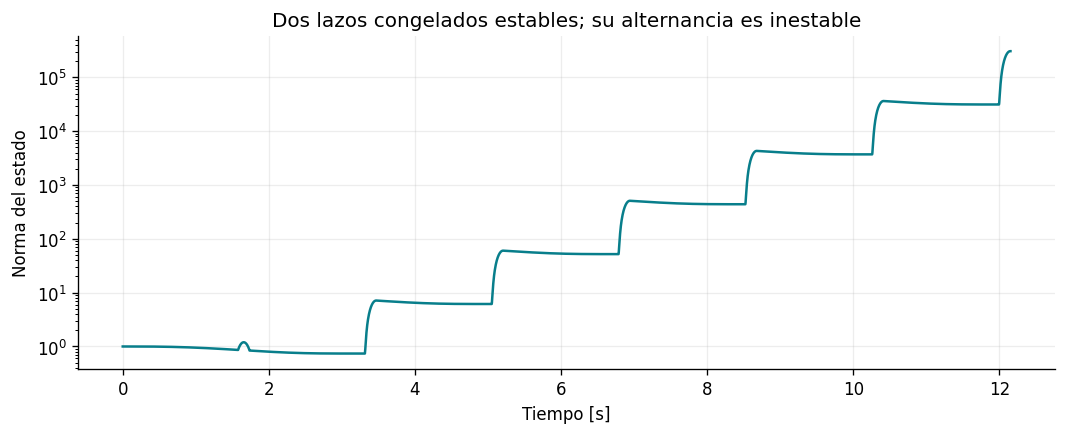

In [11]:
F1 = np.array([[0., 1.], [-1., -0.2]])
F2 = np.array([[0., 1.], [-100., -0.2]])
T1 = np.pi/(2*np.sqrt(1.0-0.1**2))
T2 = np.pi/(2*np.sqrt(100.0-0.1**2))
Phi = expm(F2*T2) @ expm(F1*T1)
print('Polos F1:', np.linalg.eigvals(F1))
print('Polos F2:', np.linalg.eigvals(F2))
print(f'T1={T1:.4f} s, T2={T2:.4f} s; radio espectral del ciclo={max(abs(np.linalg.eigvals(Phi))):.4f}')
assert max(np.linalg.eigvals(F1).real) < 0 and max(np.linalg.eigvals(F2).real) < 0
assert max(abs(np.linalg.eigvals(Phi))) > 1
q = np.array([1., 0.]); tt = [0.]; qq = [q.copy()]
for cycle in range(7):
    for F, dur in [(F1, T1), (F2, T2)]:
        base_t, base_q = tt[-1], q.copy()
        for tau in np.linspace(0, dur, 60)[1:]:
            q = expm(F*tau) @ base_q
            tt.append(base_t+tau); qq.append(q.copy())
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.semilogy(tt, np.linalg.norm(qq, axis=1))
ax.set(xlabel='Tiempo [s]', ylabel='Norma del estado',
       title='Dos lazos congelados estables; su alternancia es inestable')
plt.show()

La transición de un ciclo es
$$
e(T_1)=e^{F_1T_1}e(0),\qquad
e(T_1+T_2)=\underbrace{e^{F_2T_2}e^{F_1T_1}}_{\Phi}e(0).
$$
La matriz que actúa primero queda a la derecha. Después de $n$ ciclos, $e_n=\Phi^ne_0$. Si $\rho(\Phi)>1$, existe una dirección que crece. El cálculo utiliza exponenciales exactas, por lo que este crecimiento no es un artefacto de integración numérica.

### Un matiz crucial para este modelo: no toda adaptación es peligrosa

Si $k_p>0$ es **constante**, los estados son exactos y
$0<d_{\min}\le b(t)+k_v(t)\le d_{\max}<\infty$, la energía
$$
V=\tfrac12 k_pe^2+\tfrac12 mv^2,\qquad
\dot V=-(b+k_v)v^2\le0
$$
ya evita crecimiento energético. Con las cotas uniformes anteriores se puede obtener una función estricta añadiendo un término cruzado pequeño $\varepsilon ev$, y demostrar decaimiento uniforme. No hace falta limitar la rapidez de $k_v$ porque $V$ no depende de esa ganancia.

En la propuesta 1, recortar $k_v\ge d_{\min}-b_{\min}$ es una mejora sencilla bajo esas hipótesis. Si además se exige $k_v\ge0$ y $b\ge b_{\min}>0$, se conserva amortiguamiento positivo.

Incluso el **LQR continuo** de este modelo, con $Q_c=\operatorname{diag}(q_p,q_v)$ fijo y $R_u>0$, tiene
$$
k_p=\sqrt{q_p/R_u},\qquad
k_v=-\hat b+\sqrt{\hat b^2+2mk_p+q_v/R_u}.
$$
Por tanto, $k_p$ es constante y $k_v>0$. Con fricción real positiva y estados exactos existe esta estructura estabilizante. Sería incorrecto usar el contraejemplo anterior para afirmar que ese LQR continuo necesariamente se vuelve inestable.

Lo que falta para **los programas reales** es cubrir discretización, incertidumbre, estimación y posibles restricciones. La solución final los abordará para un modelo muestreado concreto.

### Tres caminos para una garantía

| Camino | Qué se demuestra | Qué no basta hacer |
|---|---|---|
| Lyapunov común | Un mismo $P_c\succ0$ decrece para todos los lazos admisibles. Permite cambios arbitrarios. | Revisar sólo polos o unos pocos puntos sin justificar la cobertura. |
| Lyapunov dependiente del parámetro | Se acota el término $\partial P/\partial\theta\,\dot\theta$, además de la incertidumbre. | Suavizar $\hat b$ con una constante elegida a ojo. |
| Tiempo de permanencia | Si $\dot V_i\le-\lambda V_i$ y $V_j\le\mu V_i$, basta permanecer más de $\log\mu/\lambda$ por modo, en el caso determinista considerado. | Actualizar cada segundo sin calcular esas cotas. |

Un UKF, una proyección de parámetros o un filtro pasa-bajas pueden mejorar resultados, pero no reemplazan estas demostraciones. Elegimos **Lyapunov común** porque produce un filtro de ganancias pequeño y una garantía que no exige limitar su velocidad de actualización [3, 4].

## Referencias y procedencia

1. K. J. Åström y R. M. Murray, *Feedback Systems*, capítulo de realimentación de salida y LQG. [Texto de los autores](https://www.cds.caltech.edu/~murray/books/AM08/pdf/fbs-public_24Jul2020.pdf).
2. T. D. Barfoot, *State Estimation for Robotics*, 2.ª ed., Cambridge University Press, 2024. [Página del autor y recursos](https://asrl.utias.utoronto.ca/~tdb/) · [Editorial](https://www.cambridge.org/core/books/state-estimation-for-robotics/00E53274A2F1E6CC1A55CA5C3D1C9718).
3. D. Liberzon, *Switched Systems: Stability Analysis and Control Synthesis*, notas HYCON-EECI. [Notas del autor](https://liberzon.csl.illinois.edu/teaching/Liberzon-LectureNotes.pdf). Véanse Lyapunov común y tiempo de permanencia.
4. S. Boyd, L. El Ghaoui, E. Feron y V. Balakrishnan, *Linear Matrix Inequalities in System and Control Theory*, SIAM, 1994. [Libro de los autores](https://stanford.edu/~boyd/lmibook/). Fundamentos de LMIs y análisis cuadrático robusto.
5. SciPy, [`solve_discrete_are`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_discrete_are.html). Convención de la ecuación de Riccati usada en el código.
6. CVXPY, [ejemplo de programación semidefinida](https://www.cvxpy.org/examples/basic/sdp.html). Implementación del diseño convexo fuera de línea.